# ☕ Cohort Retention & Customer LTV — Baku Coffee-Chain Loyalty App
**Daily Data Analytics Project · Day 05**

## 1. Business question
A coffee chain with 12 stores across Baku runs a loyalty app. Every customer is created with their first purchase.
Between **Jan and Aug 2026** ~17K customers signed up through four channels: organic, friend referral,
Instagram ads and a "first coffee free" voucher. On **1 May 2026** the app launched a **digital stamp card**
(every 8th coffee free).

Marketing and product want to know:
1. How quickly do customers drop off, and is retention **improving** across monthly cohorts?
2. Did the **stamp-card feature** (May launch) make cohorts stickier?
3. Which **acquisition channel** brings customers with the highest **12-month LTV**, and does each channel pay back its **CAC**?
4. Is there an early **activation signal** (a behaviour in the first 14 days) that predicts who stays?

Stack: pandas · NumPy · SciPy (curve fit, z-test) · matplotlib · seaborn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from scipy.optimize import curve_fit

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
CH_COL = {"referral": "#3A9D5D", "organic": "#2E6FBA", "instagram_ads": "#E8833A",
          "free_coffee_voucher": "#C8453B", "unknown": "#8A8F98"}
IMG = Path("images"); IMG.mkdir(exist_ok=True)
END = pd.Timestamp("2026-09-30")
FEATURE_LAUNCH = pd.Timestamp("2026-05-01")

cust_raw = pd.read_csv("data/customers.csv", parse_dates=["signup_date"])
tx_raw = pd.read_csv("data/transactions.csv", parse_dates=["txn_date"])
print("customers:", cust_raw.shape, " transactions:", tx_raw.shape)
display(cust_raw.head(3)); tx_raw.head(3)

customers: (17247, 5)  transactions: (182403, 5)


,customer_id,signup_date,channel,district,age
0,C100000,2026-01-01,instagram_ads,Narimanov,25
1,C100001,2026-01-01,organic,Sabail,30
2,C100002,2026-01-01,organic,Yasamal,33


,txn_id,customer_id,txn_date,amount_azn,store
0,T0036599,C102681,2026-03-09,9.650,Nasimi-02
1,T0066600,C105064,2026-05-27,3.460,Yasamal-02
2,T0171436,C115728,2026-09-16,5.520,Binagadi-01


## 2. Data quality check

In [2]:
is_test = tx_raw.customer_id.str.startswith("TEST")
tx_join = tx_raw.merge(cust_raw[["customer_id", "signup_date"]], on="customer_id", how="left")
dq = pd.Series({
    "transaction rows": len(tx_raw),
    "exact duplicate rows (POS double-post)": tx_raw.duplicated().sum(),
    "staff TEST accounts": cust_raw.customer_id.str.startswith("TEST").sum(),
    "transactions by TEST accounts": is_test.sum(),
    "refund rows (amount < 0)": (tx_raw.amount_azn < 0).sum(),
    "zero-amount rows (free coffee)": (tx_raw.amount_azn == 0).sum(),
    "transactions dated before signup": (tx_join.txn_date < tx_join.signup_date).sum(),
    "transactions with unknown customer": tx_join.signup_date.isna().sum(),
    "customers with missing channel": cust_raw.channel.isna().sum(),
    "customers with missing values (other cols)": cust_raw.drop(columns="channel").isna().any(axis=1).sum(),
})
dq.to_frame("count")

,count
transaction rows,182403
exact duplicate rows (POS double-post),1085
staff TEST accounts,25
transactions by TEST accounts,1511
refund rows (amount < 0),320
zero-amount rows (free coffee),1246
transactions dated before signup,150
transactions with unknown customer,0
customers with missing channel,258
customers with missing values (other cols),0


**Cleaning rules**
- Remove exact duplicate rows (same `txn_id`, same everything — POS sync double-posts).
- Remove the 25 staff `TEST` accounts and all their transactions.
- Remove transactions dated before the customer's signup (device clock errors, 400 days off).
- Keep **refunds** for revenue (net revenue), but they do **not** count as activity.
- Keep **zero-amount** rows: those are legitimate free-coffee voucher redemptions and count as activity.
- Missing channel → `unknown` (kept in totals, excluded from channel comparisons).

In [3]:
cust = cust_raw[~cust_raw.customer_id.str.startswith("TEST")].copy()
cust["channel"] = cust.channel.fillna("unknown")
cust["cohort"] = cust.signup_date.dt.to_period("M")

tx = (tx_raw.drop_duplicates()
            .merge(cust[["customer_id", "signup_date", "cohort", "channel"]], on="customer_id", how="inner"))
tx = tx[tx.txn_date >= tx.signup_date].copy()
tx["month_idx"] = ((tx.txn_date.dt.year - tx.signup_date.dt.year) * 12
                   + tx.txn_date.dt.month - tx.signup_date.dt.month)
tx["txn_month"] = tx.txn_date.dt.to_period("M")
purch = tx[tx.amount_azn >= 0]          # activity = purchases (incl. free coffee), not refunds

print(f"rows removed: {len(tx_raw) - len(tx):,}  ->  clean transactions: {len(tx):,} "
      f"({len(purch):,} purchases, {(tx.amount_azn < 0).sum()} refunds)")
print(f"customers: {len(cust):,}")

rows removed: 2,735  ->  clean transactions: 179,668 (179,348 purchases, 320 refunds)
customers: 17,222


## 3. KPIs

In [4]:
# cohort x month matrices (months observed completely up to Sep 2026)
cohort_size = cust.groupby("cohort").size()
active = purch.groupby(["cohort", "month_idx"]).customer_id.nunique().unstack()
retention = active.div(cohort_size, axis=0)
revenue = tx.groupby(["cohort", "month_idx"]).amount_azn.sum().unstack()

def pooled_ret(m):
    """Customer-weighted retention in month m over all cohorts that have reached month m."""
    ok = retention[m].notna()
    return active.loc[ok, m].sum() / cohort_size[ok].sum()

sep_active = purch[purch.txn_month == "2026-09"].customer_id.nunique()
kpi = pd.Series({
    "Customers acquired (Jan–Aug)": f"{len(cust):,}",
    "Net revenue Jan–Sep (AZN)": f"{tx.amount_azn.sum():,.0f}",
    "Purchases per customer": f"{len(purch) / len(cust):.1f}",
    "Average ticket (AZN)": f"{purch.amount_azn.mean():.2f}",
    "Month-1 retention": f"{pooled_ret(1):.1%}",
    "Month-3 retention": f"{pooled_ret(3):.1%}",
    "Month-6 retention": f"{pooled_ret(6):.1%}",
    "Active customers in Sep 2026": f"{sep_active:,}",
})
kpi.to_frame("value")

,value
Customers acquired (Jan–Aug),"17,222"
Net revenue Jan–Sep (AZN),"1,179,245"
Purchases per customer,10.4
Average ticket (AZN),6.59
Month-1 retention,58.3%
Month-3 retention,30.1%
Month-6 retention,15.2%
Active customers in Sep 2026,"5,436"


## 4. Exploratory analysis
### 4.1 Growth: signups by channel and monthly revenue

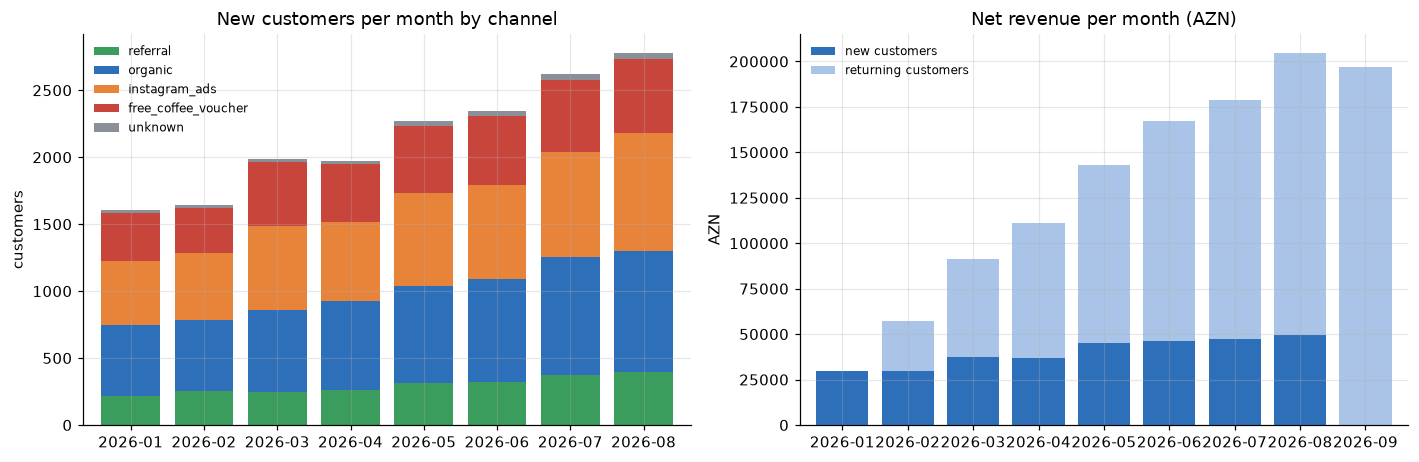

share of Aug revenue from returning customers: 75.9%


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
sign = cust.groupby(["cohort", "channel"]).size().unstack().fillna(0)
order = ["referral", "organic", "instagram_ads", "free_coffee_voucher", "unknown"]
sign[order].plot.bar(stacked=True, ax=ax[0], color=[CH_COL[c] for c in order], width=0.8)
ax[0].set(title="New customers per month by channel", xlabel="", ylabel="customers")
ax[0].legend(fontsize=8, frameon=False); ax[0].tick_params(axis="x", rotation=0)

mrev = tx.groupby(["txn_month", tx.month_idx.eq(0).map({True: "new customers", False: "returning customers"})]
                  ).amount_azn.sum().unstack()
mrev.plot.bar(stacked=True, ax=ax[1], color=["#2E6FBA", "#A9C4E6"], width=0.8)
ax[1].set(title="Net revenue per month (AZN)", xlabel="", ylabel="AZN")
ax[1].legend(fontsize=8, frameon=False); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(IMG / "growth_overview.png", bbox_inches="tight"); plt.show()
print("share of Aug revenue from returning customers:",
      f"{mrev.loc['2026-08', 'returning customers'] / mrev.loc['2026-08'].sum():.1%}")

### 4.2 Cohort retention heatmap

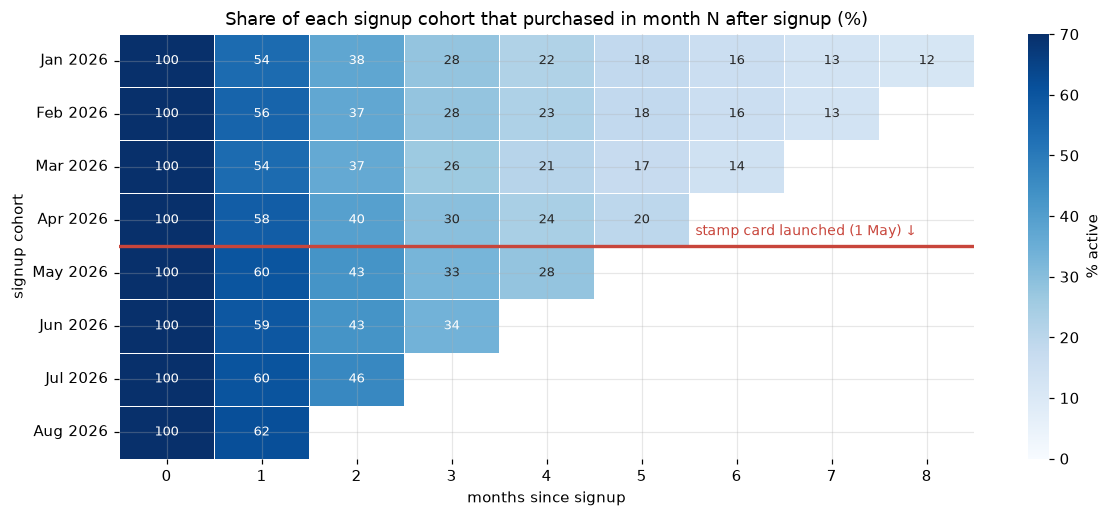

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
hm = (retention * 100).copy(); hm.index = hm.index.strftime("%b %Y")
sns.heatmap(hm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=70, cbar_kws={"label": "% active"},
            linewidths=0.5, ax=ax, annot_kws={"size": 8.5})
ax.axhline(4, color="#C8453B", lw=2.2)
ax.text(8.4, 3.85, "stamp card launched (1 May) ↓", color="#C8453B", ha="right", va="bottom", fontsize=9)
ax.set(title="Share of each signup cohort that purchased in month N after signup (%)",
       xlabel="months since signup", ylabel="signup cohort")
plt.tight_layout(); plt.savefig(IMG / "cohort_heatmap.png", bbox_inches="tight"); plt.show()

### 4.3 Retention curves by acquisition channel

In [7]:
ch_active = purch.groupby(["channel", "cohort", "month_idx"]).customer_id.nunique()
ch_size = cust.groupby(["channel", "cohort"]).size()

def channel_curve(ch, max_m=8):
    a = ch_active.loc[ch].unstack(); s = ch_size.loc[ch]
    out = {}
    for m in range(max_m + 1):
        if m in a and a[m].notna().any():
            ok = a[m].notna(); out[m] = a.loc[ok, m].sum() / s[ok].sum()
    return pd.Series(out)

channels = ["referral", "organic", "instagram_ads", "free_coffee_voucher"]
curves = pd.DataFrame({c: channel_curve(c) for c in channels})
display((curves * 100).round(1).T.rename_axis("channel").iloc[:, :7])

,0,1,2,3,4,5,6
channel,,,,,,,
referral,100.000,70.300,54.300,45.400,38.500,31.700,26.800
organic,100.000,65.000,48.500,37.600,30.100,24.000,20.000
instagram_ads,100.000,57.400,39.200,27.200,21.400,16.300,13.500
free_coffee_voucher,100.000,41.800,23.800,14.000,8.700,5.100,3.700


## 5. Analysis
### 5.1 Did the stamp card make cohorts stickier?

In [8]:
cust["era"] = np.where(cust.signup_date >= FEATURE_LAUNCH, "after (May–Aug)", "before (Jan–Apr)")
first3 = purch[purch.month_idx.between(1, 3)]
rows = []
for m in [1, 2, 3]:
    # only cohorts that have completed month m, so both groups are measured on the same window
    eligible = cust[(cust.cohort + m) <= pd.Period("2026-09", "M")]
    act = set(purch.loc[purch.month_idx == m, "customer_id"])
    for era, g in eligible.groupby("era"):
        rows.append({"month": m, "era": era, "n": len(g), "retained": g.customer_id.isin(act).sum()})
r = pd.DataFrame(rows); r["rate"] = r.retained / r.n
res = []
for m, g in r.groupby("month"):
    b, a = g.set_index("era").loc["before (Jan–Apr)"], g.set_index("era").loc["after (May–Aug)"]
    p = (a.retained + b.retained) / (a.n + b.n)
    z = (a.rate - b.rate) / np.sqrt(p * (1 - p) * (1 / a.n + 1 / b.n))
    res.append({"month": f"M{m}", "before": b.rate, "after": a.rate, "diff_pp": (a.rate - b.rate) * 100,
                "rel_lift": a.rate / b.rate - 1, "p_value": 2 * stats.norm.sf(abs(z)), "n_after": int(a.n)})
feature = pd.DataFrame(res).set_index("month")
display(feature)

# confounder check: did the channel mix change between eras?
mix = pd.crosstab(cust.era, cust.channel, normalize="index")[channels]
display((mix * 100).round(1))
chi2, p_mix, *_ = stats.chi2_contingency(pd.crosstab(cust.era, cust.channel)[channels])
print(f"channel-mix chi² p = {p_mix:.2f}")

# channel-adjusted: compare within each channel (M2 retention)
adj = []
for ch in channels:
    e = cust[(cust.channel == ch) & ((cust.cohort + 2) <= pd.Period("2026-09", "M"))]
    act2 = e.customer_id.isin(set(purch.loc[purch.month_idx == 2, "customer_id"]))
    adj.append(act2.groupby(e.era).mean().rename(ch))
adj = pd.DataFrame(adj)[["before (Jan–Apr)", "after (May–Aug)"]]
adj["rel_lift"] = adj.iloc[:, 1] / adj.iloc[:, 0] - 1
adj

,before,after,diff_pp,rel_lift,p_value,n_after
month,,,,,,
M1,0.554,0.604,4.931,0.089,0.000,10012
M2,0.377,0.443,6.578,0.174,0.000,7232
M3,0.280,0.334,5.382,0.192,0.000,4612


channel,referral,organic,instagram_ads,free_coffee_voucher
era,,,,
after (May–Aug),14.000,32.700,30.600,21.100
before (Jan–Apr),13.600,32.500,30.300,22.300


channel-mix chi² p = 0.34


era,before (Jan–Apr),after (May–Aug),rel_lift
referral,0.516,0.569,0.101
organic,0.453,0.517,0.141
instagram_ads,0.367,0.418,0.140
free_coffee_voucher,0.194,0.282,0.451


The channel mix is the same before and after the launch, and the lift appears **inside every channel**, so it is not
a mix effect. Caveat: this is a before/after comparison, not a randomised test — seasonality could contribute
(although summer usually *lowers* coffee visits, which would bias against the feature).

### 5.2 Activation signal: a 2nd visit within 14 days

In [9]:
first = purch.merge(cust[["customer_id"]], on="customer_id")
early = (purch[(purch.txn_date - purch.signup_date).dt.days.between(0, 13)]
         .groupby("customer_id").size())
cust["activated"] = cust.customer_id.map(early).fillna(0).ge(2)

elig = cust[(cust.cohort + 3) <= pd.Period("2026-09", "M")].copy()
act3 = set(purch.loc[purch.month_idx == 3, "customer_id"])
elig["retained_m3"] = elig.customer_id.isin(act3)
act_tab = elig.groupby("activated").agg(customers=("customer_id", "size"), m3_retention=("retained_m3", "mean"))
display(act_tab)
print(f"activation rate overall: {cust.activated.mean():.1%}")
display(cust[cust.channel != "unknown"].groupby("channel").activated.mean().sort_values().to_frame("activation_rate"))

,customers,m3_retention
activated,,
False,3913,0.125
True,7909,0.389


activation rate overall: 66.3%


,activation_rate
channel,
free_coffee_voucher,0.557
instagram_ads,0.660
organic,0.703
referral,0.739


### 5.3 12-month LTV, CAC and payback by channel
Retention beyond the observed window is extrapolated with a **power-law curve** `r(m) = a·m^(−b)` fitted on months 1–8
per channel (fits retention decay well because of customer heterogeneity). LTV = Σ retention(m) × revenue per active
customer(m) × **contribution margin 35%** (after beans, milk, cups, barista time and card fees). CAC per channel comes from the
marketing budget (assumed figures below; the voucher CAC includes the free coffee itself). `payback_months` = months
of revenue needed to recover CAC (1 = the signup month).

In [10]:
MARGIN = 0.35
CAC = {"referral": 12.0, "organic": 3.0, "instagram_ads": 22.0, "free_coffee_voucher": 14.0}   # AZN per new customer
H = 12
power = lambda m, a, b: a * np.power(m, -b)

ltv_rows, ltv_curves = [], {}
for ch in channels:
    c = curves[ch].dropna()
    (a, b), _ = curve_fit(power, c.index[1:].values.astype(float), c.values[1:], p0=(0.6, 0.8))
    ret = np.array([c.iloc[0]] + [c[m] if m in c.index else power(m, a, b) for m in range(1, H)])
    pc = purch[purch.channel == ch]
    arpa = (tx[tx.channel == ch].groupby("month_idx").amount_azn.sum()
            / pc.groupby("month_idx").customer_id.nunique())          # net revenue per active customer
    arpa_m = np.array([arpa.get(m, arpa.loc[1:].mean()) for m in range(H)])
    cum_gm = np.cumsum(ret * arpa_m) * MARGIN
    ltv_curves[ch] = cum_gm
    payback = int(np.argmax(cum_gm >= CAC[ch])) + 1 if (cum_gm >= CAC[ch]).any() else None
    n_ch = (cust.channel == ch).sum()
    ltv_rows.append({"channel": ch, "customers": n_ch, "M1_ret": c[1], "M3_ret": c[3],
                     "decay_b": b, "rev_per_active_month": arpa.loc[1:].mean(),
                     "LTV12_margin": cum_gm[-1], "CAC": CAC[ch],
                     "LTV_to_CAC": cum_gm[-1] / CAC[ch], "payback_months": payback})
ltv = pd.DataFrame(ltv_rows).set_index("channel")
ltv

,customers,M1_ret,M3_ret,decay_b,rev_per_active_month,LTV12_margin,CAC,LTV_to_CAC,payback_months
channel,,,,,,,,,
referral,2379,0.703,0.454,0.519,40.190,61.377,12.000,5.115,2
organic,5616,0.650,0.376,0.605,37.613,48.349,3.000,16.116,1
instagram_ads,5255,0.574,0.272,0.788,33.112,31.737,22.000,1.443,5
free_coffee_voucher,3714,0.418,0.140,1.133,32.361,15.793,14.000,1.128,7


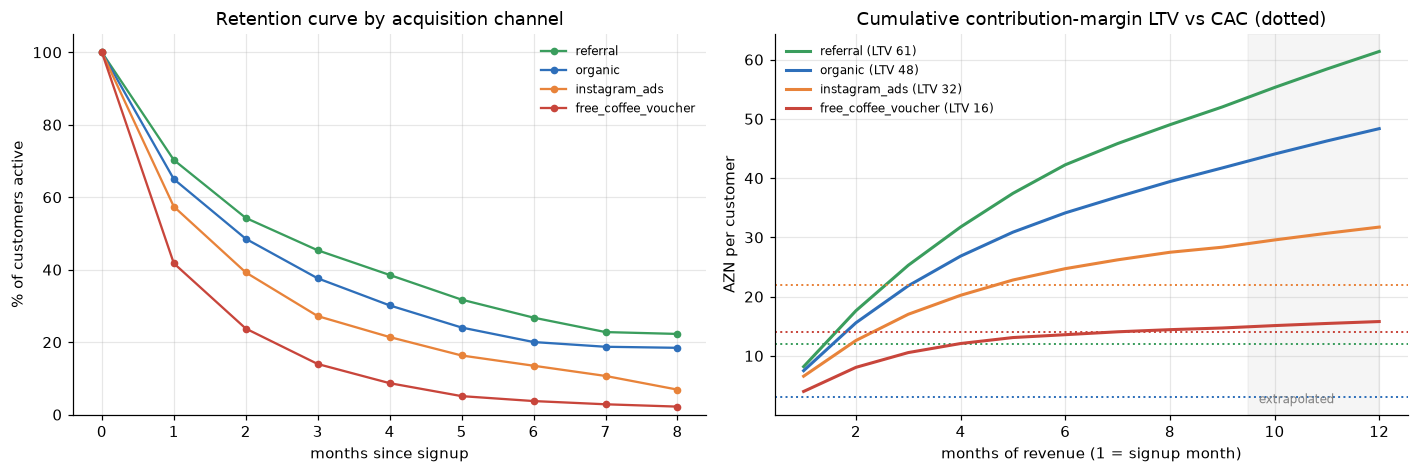

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for ch in channels:
    c = curves[ch].dropna()
    ax[0].plot(c.index, c.values * 100, "o-", color=CH_COL[ch], label=ch, ms=4)
ax[0].set(title="Retention curve by acquisition channel", xlabel="months since signup",
          ylabel="% of customers active", ylim=(0, 105))
ax[0].legend(frameon=False, fontsize=8)

for ch in channels:
    ax[1].plot(range(1, H + 1), ltv_curves[ch], color=CH_COL[ch], lw=2, label=f"{ch} (LTV {ltv_curves[ch][-1]:.0f})")
    ax[1].axhline(CAC[ch], color=CH_COL[ch], ls=":", lw=1.3)
ax[1].set(title="Cumulative contribution-margin LTV vs CAC (dotted)",
          xlabel="months of revenue (1 = signup month)", ylabel="AZN per customer")
ax[1].axvspan(9.5, H, color="grey", alpha=0.08); ax[1].text(9.7, 2, "extrapolated", fontsize=8, color="grey")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "channel_retention_ltv.png", bbox_inches="tight"); plt.show()

### 5.4 What is the stamp card worth?

In [12]:
# apply the observed M1-M3 relative lift to months 1..11 of the blended curve (conservative: no compounding)
lift = feature.rel_lift.mean()
blend_ret = np.array([pooled_ret(0)] + [pooled_ret(m) if m <= 8 else np.nan for m in range(1, H)])
mask = np.isnan(blend_ret)
(a, b), _ = curve_fit(power, np.arange(1, 9, dtype=float), blend_ret[1:9], p0=(0.6, 0.8))
blend_ret[mask] = power(np.arange(H)[mask].astype(float), a, b)
arpa_all = (tx.groupby("month_idx").amount_azn.sum() / purch.groupby("month_idx").customer_id.nunique())
arpa_all = np.array([arpa_all.get(m, arpa_all.loc[1:].mean()) for m in range(H)])
base_ltv = (blend_ret * arpa_all).sum() * MARGIN
new_ltv = (blend_ret * np.r_[1, np.full(H - 1, 1 + lift)] * arpa_all).sum() * MARGIN
monthly_new = cust[cust.signup_date >= "2026-06-01"].groupby("cohort").size().mean()
print(f"average M1–M3 relative lift: {lift:.1%}")
print(f"blended 12-month LTV: {base_ltv:.1f} -> {new_ltv:.1f} AZN contribution margin per customer (+{new_ltv - base_ltv:.1f})")
print(f"≈ {(new_ltv - base_ltv) * monthly_new * 12:,.0f} AZN extra contribution margin per year at {monthly_new:,.0f} new customers / month")

average M1–M3 relative lift: 15.2%
blended 12-month LTV: 37.5 -> 42.2 AZN contribution margin per customer (+4.7)
≈ 145,661 AZN extra contribution margin per year at 2,582 new customers / month


## 6. Findings & recommendations

In [13]:
best = ltv.LTV_to_CAC.idxmax(); worst = ltv.LTV_to_CAC.idxmin()
findings = pd.DataFrame([
    ["Retention", f"Only {pooled_ret(1):.0%} of new customers buy again in month 1 and {pooled_ret(3):.0%} in month 3; "
                  f"the curve flattens after month 4 (loyal core ≈ {pooled_ret(6):.0%}).",
     "Focus win-back on days 15–45, where most customers are lost."],
    ["Stamp card", f"Post-launch cohorts retain {feature.rel_lift.mean():.0%} better in M1–M3 "
                   f"(M2: {feature.loc['M2','before']:.1%} → {feature.loc['M2','after']:.1%}, p < 0.001), in every channel.",
     "Keep the stamp card; A/B test a 6-stamp vs 8-stamp card to confirm causality and tune cost."],
    ["Channels", f"{best} has the best LTV/CAC ({ltv.loc[best,'LTV_to_CAC']:.1f}×); "
                 f"{worst} returns {ltv.loc[worst,'LTV_to_CAC']:.1f}× and needs {ltv.loc[worst,'payback_months']} months to pay back.",
     "Shift budget from free-coffee vouchers to referral; require a 2nd purchase before voucher value is released."],
    ["Instagram ads", f"LTV/CAC {ltv.loc['instagram_ads','LTV_to_CAC']:.1f}×, payback in {ltv.loc['instagram_ads','payback_months']} months — profitable but expensive.",
     "Do not scale at current CAC (1.4× is thin); bring CAC to ≤ 15 AZN (≈ 2×) via lookalikes of referral customers."],
    ["Activation", f"Customers with a 2nd visit within 14 days: M3 retention {act_tab.loc[True,'m3_retention']:.0%} vs "
                   f"{act_tab.loc[False,'m3_retention']:.0%}.",
     "Make '2nd coffee in 14 days' the onboarding North-Star: push + double stamp on day 3–7."],
], columns=["Area", "Finding", "Recommendation"])
findings.style.set_properties(**{"text-align": "left", "white-space": "normal"}).hide(axis="index")

Area,Finding,Recommendation
Retention,Only 58% of new customers buy again in month 1 and 30% in month 3; the curve flattens after month 4 (loyal core ≈ 15%).,"Focus win-back on days 15–45, where most customers are lost."
Stamp card,"Post-launch cohorts retain 15% better in M1–M3 (M2: 37.7% → 44.3%, p < 0.001), in every channel.",Keep the stamp card; A/B test a 6-stamp vs 8-stamp card to confirm causality and tune cost.
Channels,organic has the best LTV/CAC (16.1×); free_coffee_voucher returns 1.1× and needs 7 months to pay back.,Shift budget from free-coffee vouchers to referral; require a 2nd purchase before voucher value is released.
Instagram ads,"LTV/CAC 1.4×, payback in 5 months — profitable but expensive.",Do not scale at current CAC (1.4× is thin); bring CAC to ≤ 15 AZN (≈ 2×) via lookalikes of referral customers.
Activation,Customers with a 2nd visit within 14 days: M3 retention 39% vs 12%.,Make '2nd coffee in 14 days' the onboarding North-Star: push + double stamp on day 3–7.


> ℹ️ The dataset is **synthetic** (fixed seed) and modelled on typical loyalty-app behaviour. CAC figures and the 35%
contribution margin are assumptions for illustration. The stamp-card effect is a before/after estimate, not an experiment.